Bonus: LightGBM pe aceleasi features

In aceasta parte implementam si optimizam un al doilea algoritm de boosted trees, LightGBM, si il comparam cu XGBoost. Pentru ca comparatia sa fie corecta, folosim exact aceleasi date, acelasi encoding (one-hot), aceeasi impartire train/test, aceleasi 5 folduri de validare, aceleasi ponderi pe clase si aceleasi metrici ca in partile B si C. Toate functiile folosite sunt in src/metrics_eval.py (sectiunea LightGBM de la final).

Notebook-ul urmeaza aceiasi pasi ca pentru XGBoost:
- modelul de baza, curba de invatare si arborii (ca in partea B)
- importanta features si metricile pe test
- experimente manuale cu hiperparametrii (ca in partea B)
- optimizarea cu Optuna (ca in partea C)
- comparatia finala XGBoost vs LightGBM: constructia arborilor, procesul de invatare si rezultatele

In [1]:
# Configurarea cailor: gasim radacina proiectului (folderul cu pyproject.toml)
import sys
import time
import warnings
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
assert ROOT is not None, "Ruleaza notebook-ul din interiorul folderului proiectului (ames-housing-ML)."

DATA_PROCESSED = ROOT / "data" / "processed"
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import metrics_eval

# Aceeasi configuratie ca in partile B si C
ENCODING = "onehot"
X, y, preprocessor = metrics_eval.load_data(DATA_PROCESSED / "df_fe.csv", ENCODING)
X_train, X_test, y_train, y_test = metrics_eval.make_split(X, y, test_size=0.2, stratify=True)

print("X:", X.shape, "| train:", X_train.shape, "| test:", X_test.shape)

X: (2930, 92) | train: (2344, 92) | test: (586, 92)


Modelul LightGBM de baza

Antrenam LightGBM cu hiperparametri de baza alesi paralel cu cei de la XGBoost din partea B (learning_rate 0.1, subsample 0.8, colsample_bytree 0.8, reg_lambda 1, fara ponderi pe clase). Diferenta principala este parametrul de complexitate: XGBoost foloseste max_depth = 4, iar LightGBM foloseste num_leaves = 31 (numarul maxim de frunze), fara limita de adancime. La fel ca la XGBoost, numarul de runde este ales cu early stopping pe o parte de validare scoasa din train, apoi modelul este reantrenat pe tot train-ul cu acest numar de runde.

runde folosite: 50 | arbori in model: 300


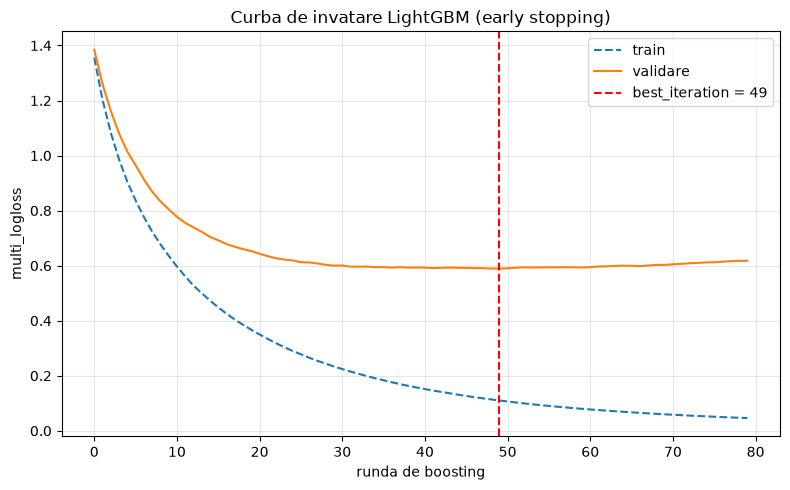

In [2]:
model_lgb_base = metrics_eval.fit_lgb(X_train, y_train, preprocessor, use_class_weight=False)
clf = model_lgb_base.named_steps["classifier"]
print("runde folosite:", model_lgb_base._early_stopping_selected_rounds,
      "| arbori in model:", clf.booster_.num_trees())
metrics_eval.plot_lgb_training_curve(model_lgb_base)

Interpretarea curbei de invatare

Early stopping a oprit antrenarea la best_iteration = 49, deci modelul de baza foloseste 50 de runde, adica 300 de arbori (6 pe runda, cate unul pentru fiecare clasa). Pe validare, logloss-ul scade repede in primele 20-30 de runde si se stabilizeaza in jur de 0.59, apoi incepe sa creasca usor dupa runda 60. Pe train, logloss-ul continua sa scada spre 0.05: diferenta mare dintre cele doua curbe arata overfitting.

Pentru comparatie, modelul XGBoost de baza (aceiasi parametri, aceeasi validare) a avut nevoie de aproximativ 115-120 de runde. LightGBM ajunge la optim de peste doua ori mai repede, pentru ca fiecare arbore al sau este mult mai mare (pana la 31 de frunze, fata de cel mult 16 la XGBoost cu max_depth = 4): fiecare runda invata mai mult, dar si supra-ajusteaza mai repede.

Arborii LightGBM

La fel ca la XGBoost, in clasificarea multiclasa fiecare runda adauga cate un arbore pentru fiecare clasa, deci indexul unui arbore este runda * 6 + clasa. Desenam primul arbore al clasei 0 (<100k) si arborele aceleiasi clase din ultima runda. Nodurile albastre sunt split-uri (ramura "da" este cea in care conditia este adevarata), iar frunzele arata valoarea adaugata la scorul clasei: verde pozitiv, rosu negativ.

,runda,clasa,noduri,frunze,adancime_max,radacina,gain_total
tree,,,,,,,
0,0,0,37,19,9,TotalSF,746.53
294,49,0,53,27,10,Fireplace Qu,10.76


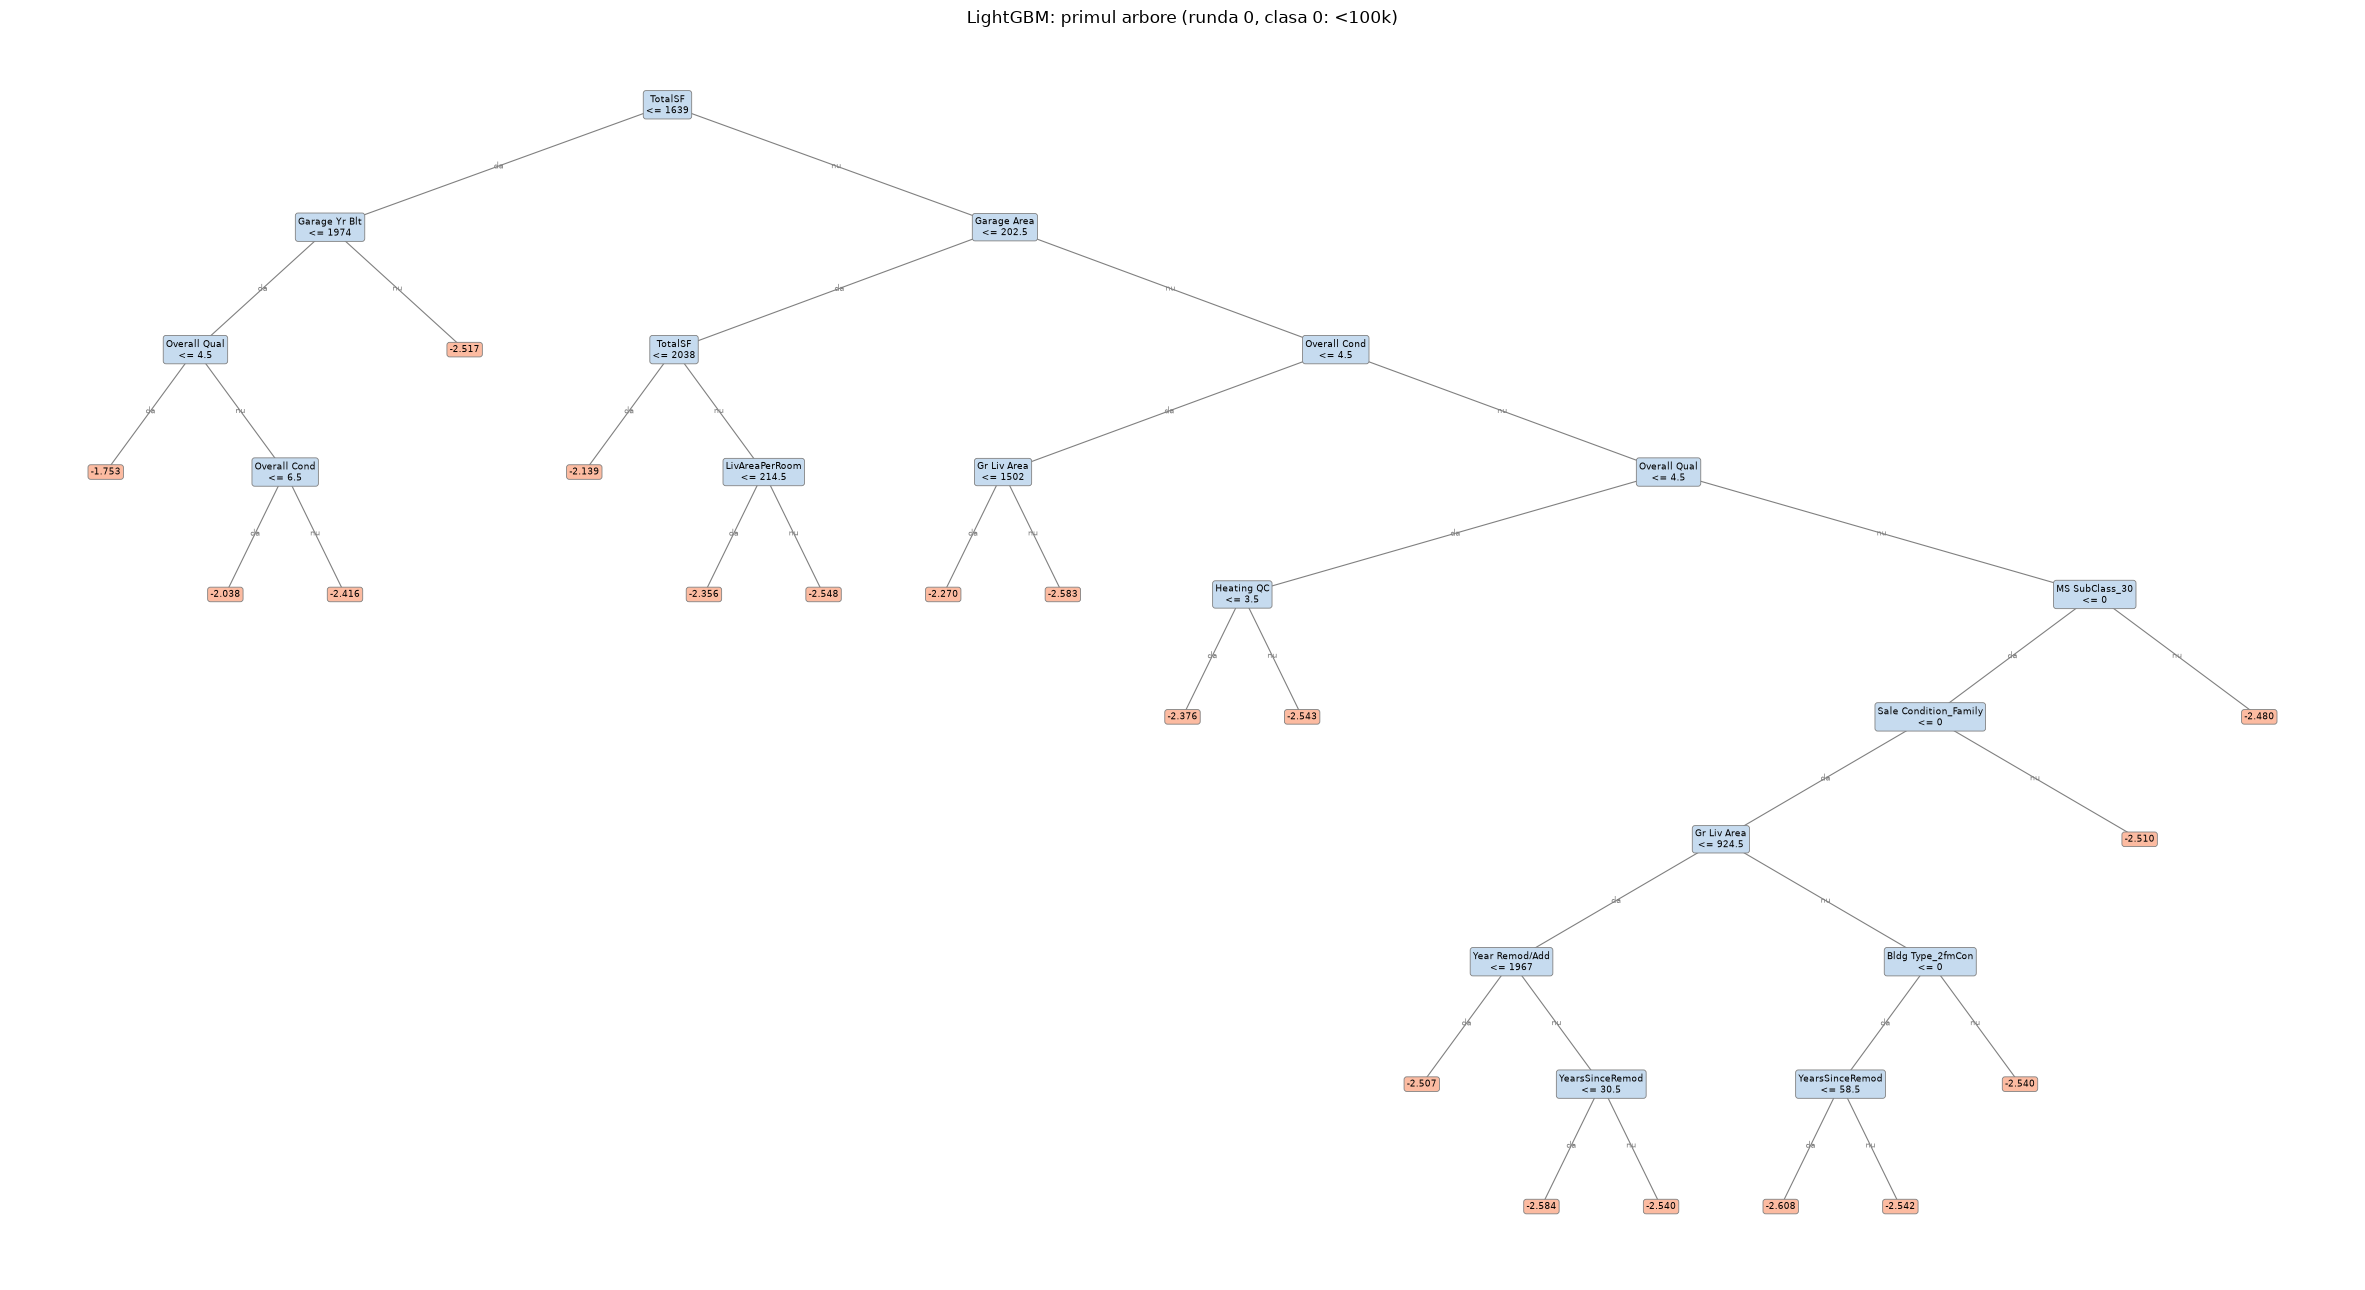

In [3]:
tree_stats_base = metrics_eval.tree_structure_stats(model_lgb_base)
first_idx = metrics_eval.first_tree_idx_any(model_lgb_base, class_idx=0)
last_idx = metrics_eval.last_tree_idx_any(model_lgb_base, class_idx=0)
display(tree_stats_base.loc[[first_idx, last_idx]].round(2))
metrics_eval.plot_tree_generic(model_lgb_base, first_idx, "LightGBM: primul arbore (runda 0, clasa 0: <100k)")

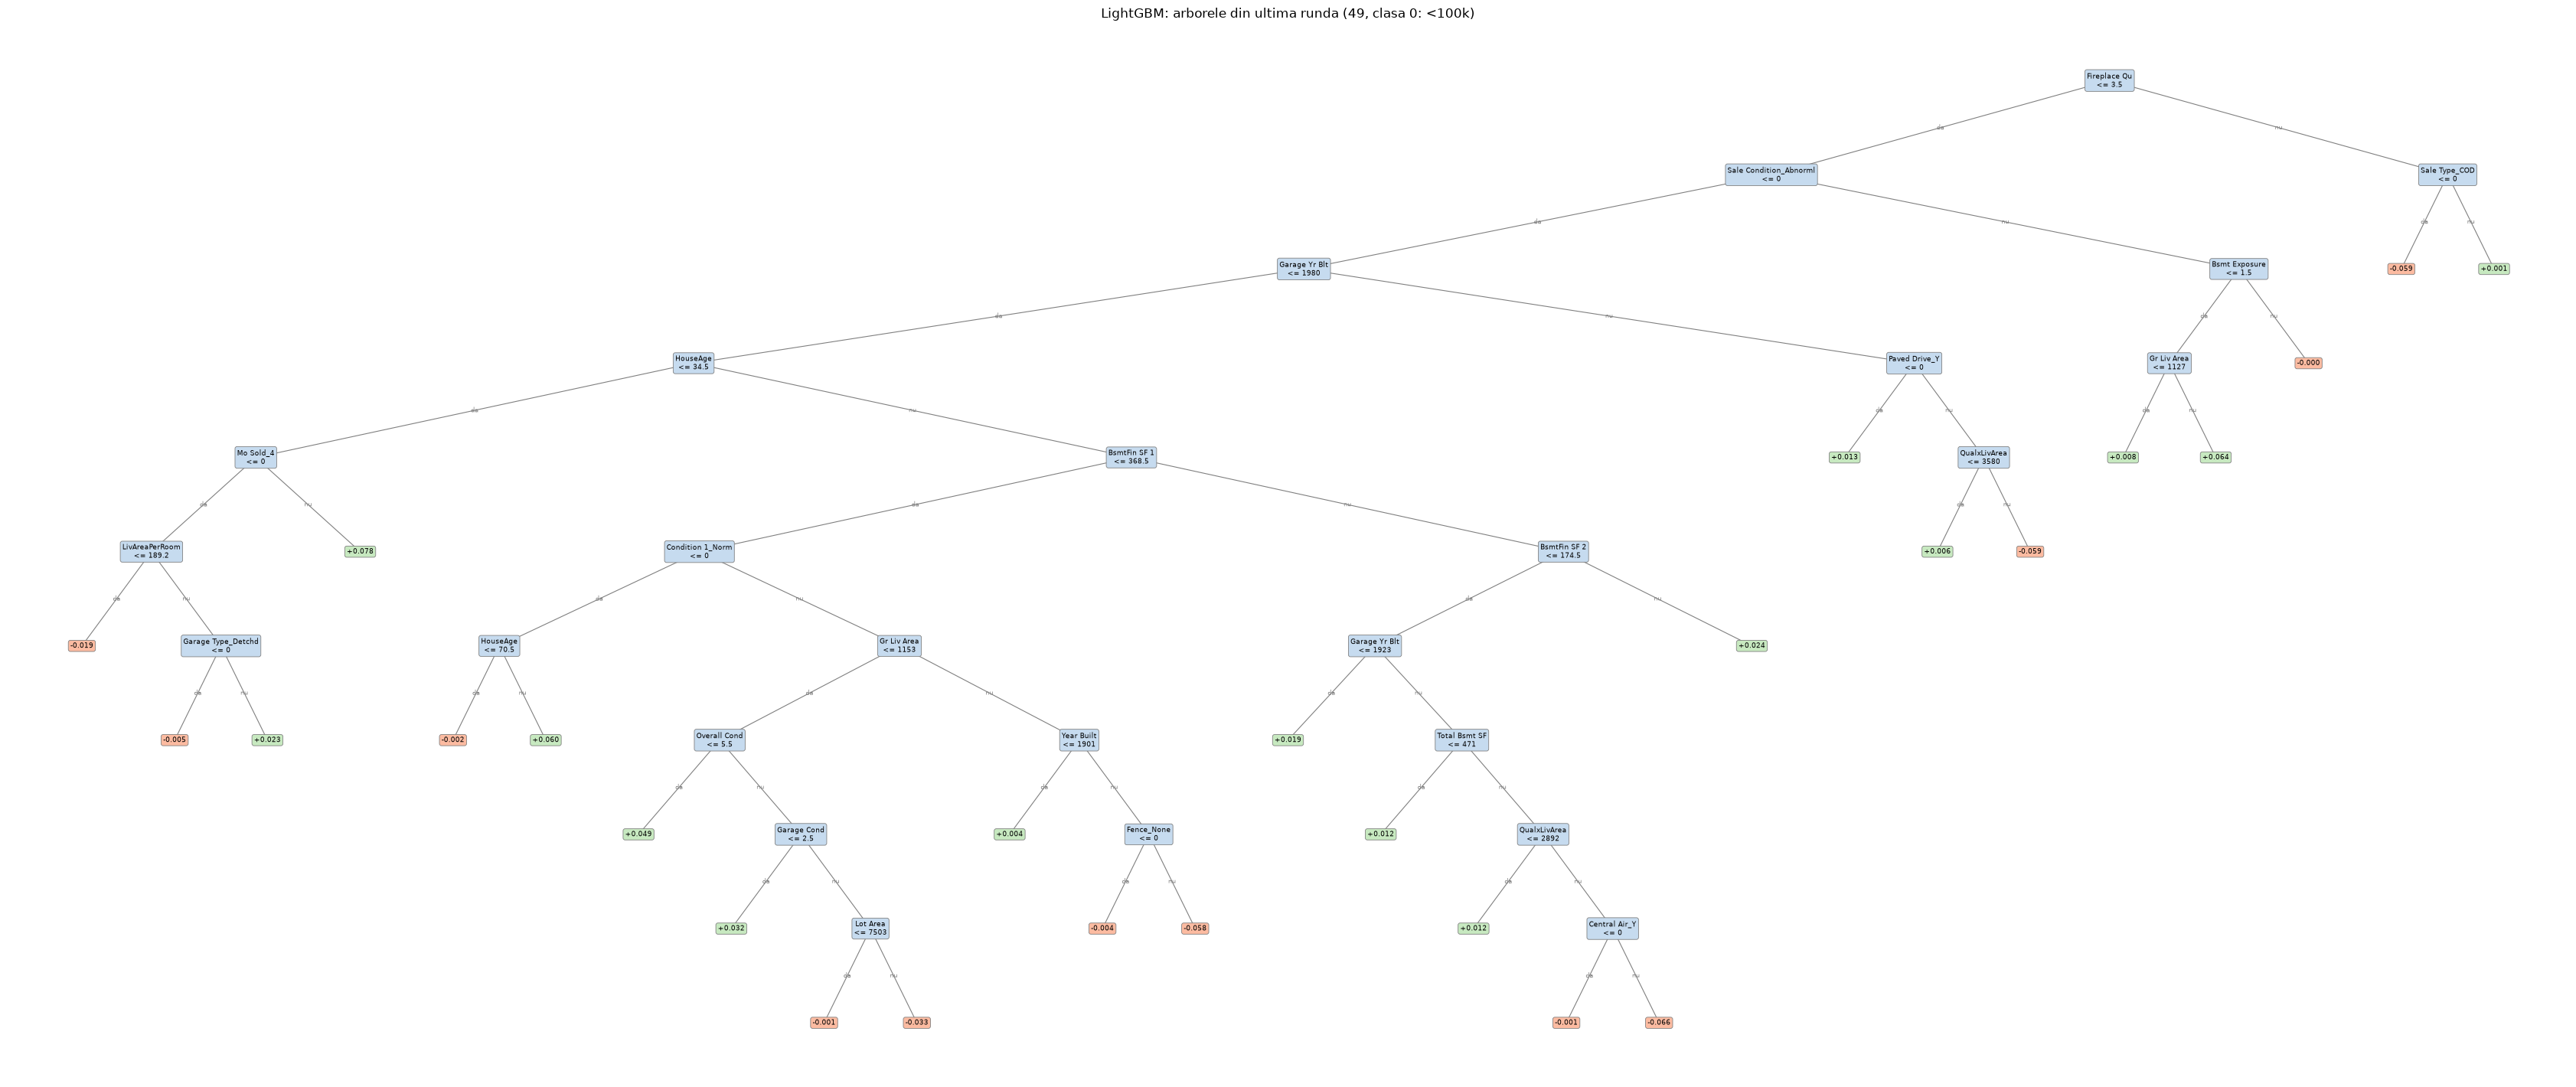

In [4]:
metrics_eval.plot_tree_generic(model_lgb_base, last_idx,
                               f"LightGBM: arborele din ultima runda ({last_idx // 6}, clasa 0: <100k)")

Interpretarea arborilor

Primul arbore al clasei 0 (<100k) are 37 de noduri, 19 frunze si adancimea 9, iar radacina este TotalSF <= 1639: prima intrebare pe care o pune modelul pentru a recunoaste casele ieftine este daca suprafata totala este mica. Arborele nu este echilibrat: unele ramuri se opresc dupa 2-3 split-uri, altele coboara pana la adancimea 9, acolo unde casele sunt mai greu de separat.

Arborele aceleiasi clase din ultima runda (49) are 53 de noduri, 27 de frunze si adancimea 10, dar gain-ul total este doar 10.8, fata de 746.5 la primul arbore. Este comportamentul tipic al boosting-ului: primii arbori invata structura mare a datelor (suprafata, calitatea), iar arborii de la final corecteaza doar erori mici ramase, deci contribuie foarte putin. Radacina lui (Fireplace Qu) este o caracteristica secundara, aleasa pentru ca erorile ramase nu mai sunt explicate de suprafata sau calitate.

Constructia arborilor: XGBoost vs LightGBM

Pentru comparatie antrenam si modelul XGBoost de baza din partea B (aceiasi parametri, aceeasi functie fit_xgb) si comparam forma tuturor arborilor din cele doua modele: cate frunze are fiecare arbore, cat de adanc este si la ce adancime se afla frunzele.

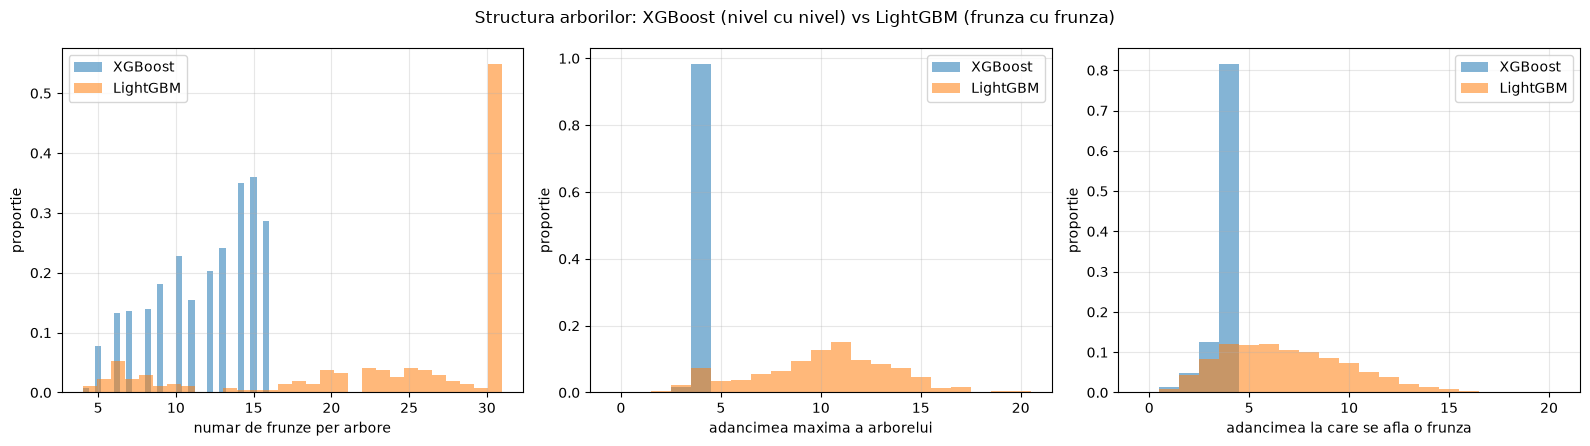

,arbori,frunze/arbore (medie),adancime max (medie),adancime max (maxim),adancimea frunzelor (medie),adancimea frunzelor (std)
model,,,,,,
XGBoost,714,11.75,3.98,4,3.74,0.61
LightGBM,300,24.40,10.06,20,6.91,3.15


In [5]:
model_xgb_base = metrics_eval.fit_xgb(X_train, y_train, preprocessor, use_class_weight=False)
structure_base = metrics_eval.plot_structure_comparison({"XGBoost": model_xgb_base, "LightGBM": model_lgb_base})
display(structure_base.round(2))

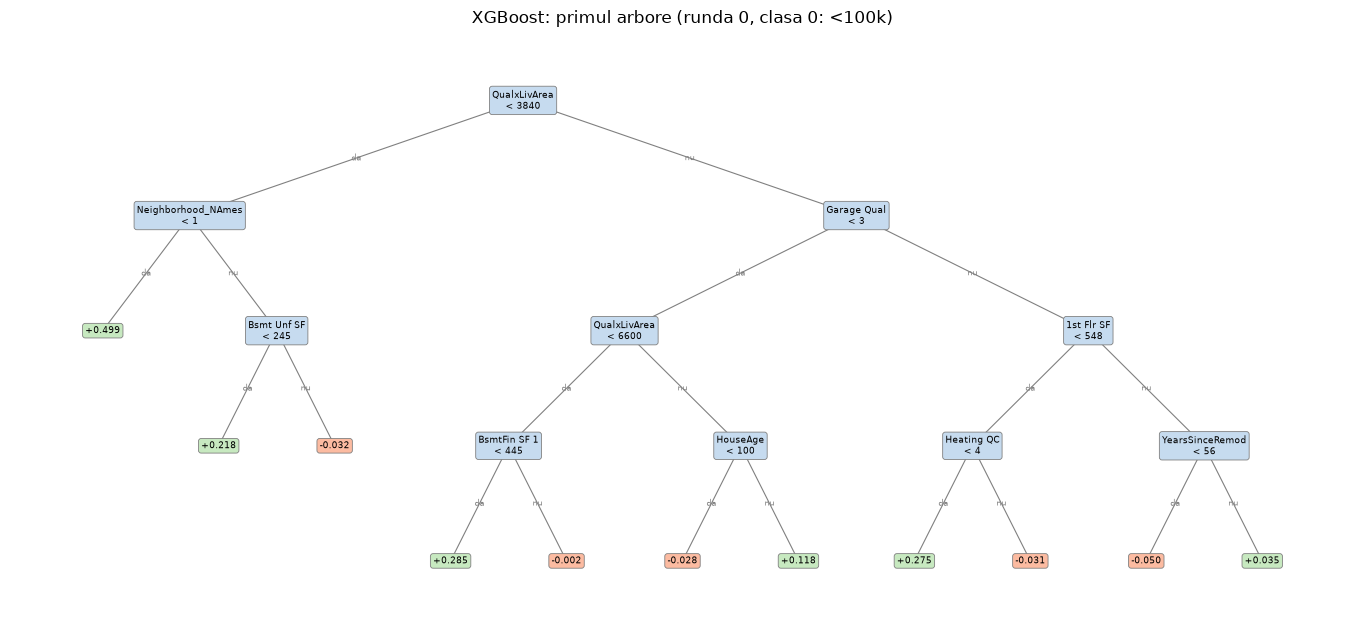

In [6]:
first_xgb = metrics_eval.first_tree_idx_any(model_xgb_base, class_idx=0)
metrics_eval.plot_tree_generic(model_xgb_base, first_xgb, "XGBoost: primul arbore (runda 0, clasa 0: <100k)")

Constructia arborilor: nivel cu nivel vs frunza cu frunza

Graficele arata cea mai importanta diferenta dintre cei doi algoritmi:
- XGBoost creste arborii nivel cu nivel (level-wise): imparte toate nodurile de pe un nivel, apoi trece la nivelul urmator, pana la max_depth. Cu max_depth = 4, aproape toti arborii au exact adancimea 4 (media 3.98), cel mult 16 frunze (media 11.75), iar frunzele sunt aproape toate la aceeasi adancime (media 3.74, deviatia standard doar 0.61). Arborii sunt scurti si echilibrati.
- LightGBM creste arborii frunza cu frunza (leaf-wise): la fiecare pas imparte frunza care aduce cel mai mare castig, oriunde s-ar afla, pana ajunge la num_leaves = 31. Arborii au in medie 24.4 frunze, adancimea medie 10.1 si pot ajunge pana la adancimea 20, iar frunzele sunt raspandite pe toate nivelurile (adancimea medie 6.9, deviatia standard 3.15). Arborii sunt adanci si dezechilibrati: ramurile cu case greu de separat sunt adancite mult, celelalte raman scurte.

Se vede si pe primii arbori desenati: cel de la XGBoost este simetric, cu toate frunzele la adancimea 4, iar cel de la LightGBM are ramuri foarte diferite ca lungime.

Strategia frunza cu frunza reduce mai repede eroarea cu acelasi numar de frunze, de aceea LightGBM are nevoie de mai putine runde (300 de arbori fata de 714 la XGBoost). Dezavantajul este ca, pe un set de date mic ca al nostru (2344 de case in train), ramurile foarte adanci ajung sa contina putine case si modelul supra-ajusteaza usor. De aceea, la LightGBM parametrii care limiteaza frunzele (num_leaves, min_child_samples) sunt mai importanti decat max_depth.

Importanta features

Calculam importanta la fel ca in partea B: gain (castigul mediu adus de split-urile pe un feature) si split (de cate ori este folosit un feature). Coloanele one-hot sunt adunate inapoi la feature-ul original. Pentru comparatia cu XGBoost folosim procente din gain-ul total si din numarul total de split-uri, pentru ca valorile absolute ale gain-ului nu sunt calculate pe aceeasi scara in cele doua biblioteci.

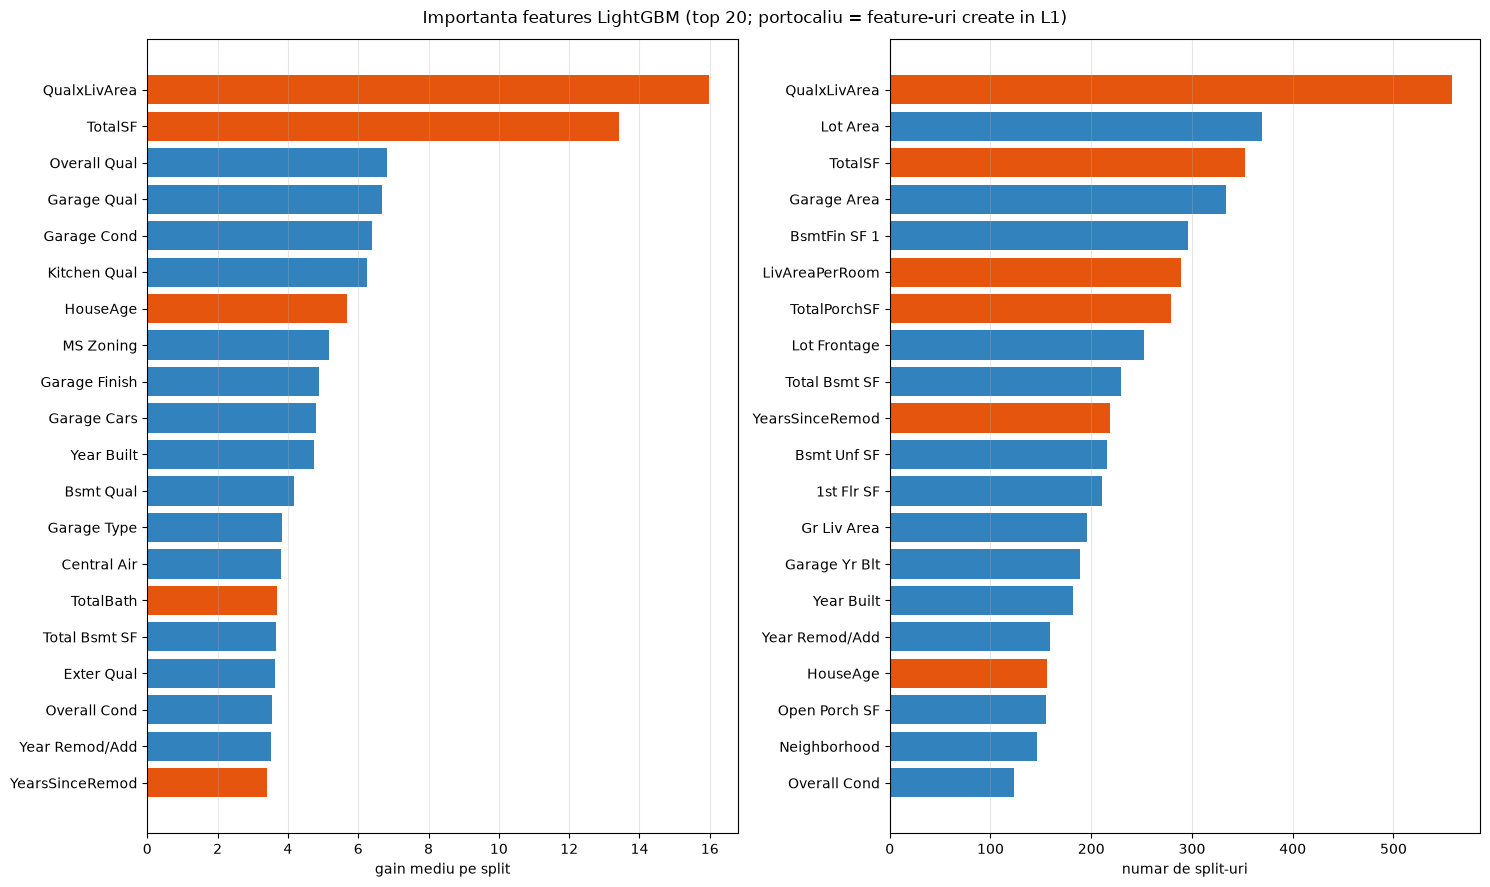

,gain,total_gain,split,rank_gain,rank_split
QualxLivArea,15.99,8921.25,558.0,1,1
TotalSF,13.41,4735.30,353.0,2,3
Overall Qual,6.82,832.07,122.0,3,21
Garage Qual,6.68,167.02,25.0,4,51
Garage Cond,6.40,140.85,22.0,5,54
Kitchen Qual,6.24,287.16,46.0,6,37
HouseAge,5.67,884.22,156.0,7,17
MS Zoning,5.17,217.35,42.0,8,39
Garage Finish,4.88,253.72,52.0,9,33
Garage Cars,4.79,138.95,29.0,10,47


In [7]:
imp_lgb = metrics_eval.plot_lgb_importance(model_lgb_base, top=20)
display(imp_lgb.head(10).round(2))

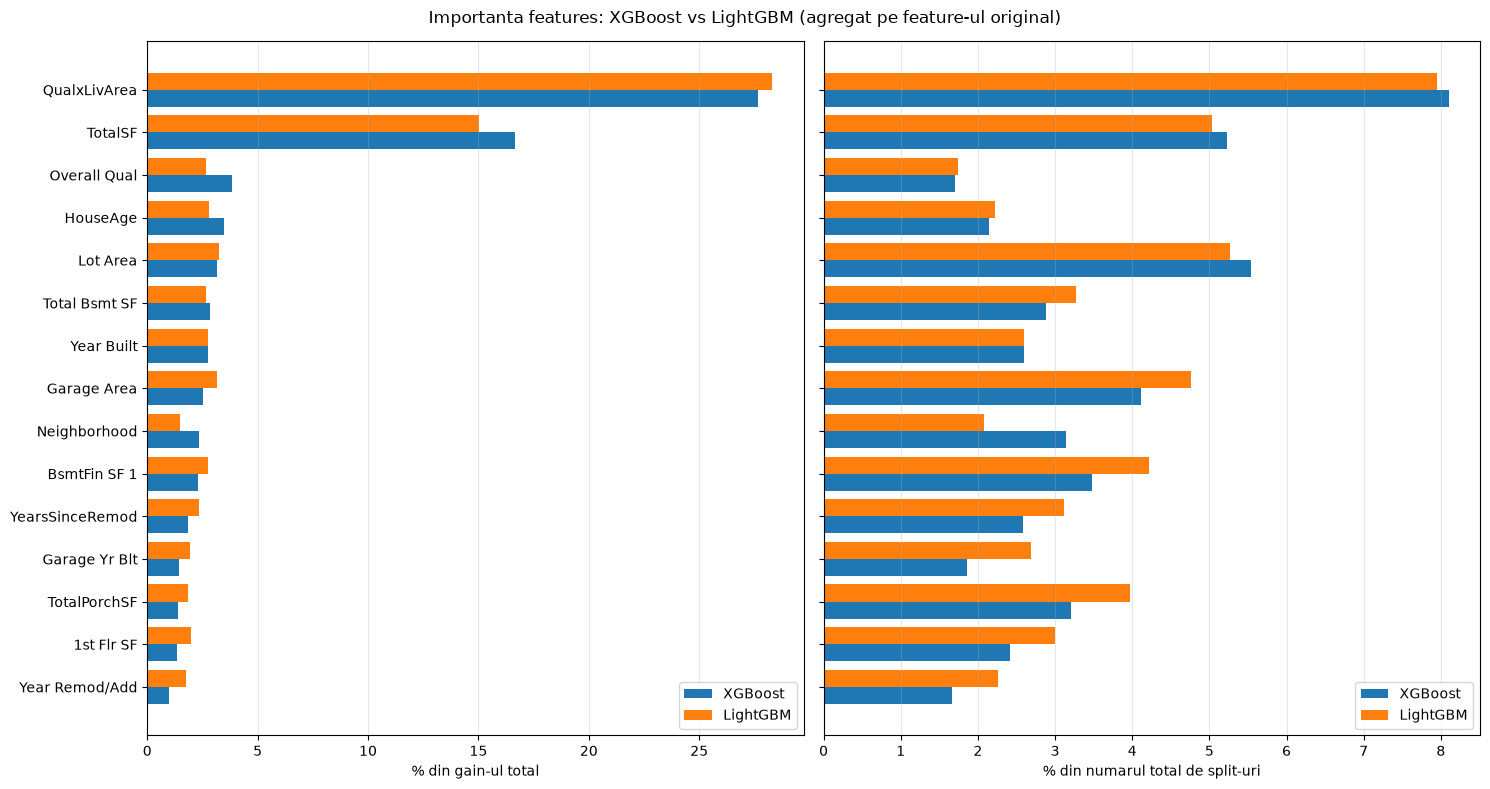

Corelatia Spearman intre clasamentele dupa gain: 0.973


,XGBoost % gain,LightGBM % gain,XGBoost % split,LightGBM % split
QualxLivArea,27.68,28.32,8.10,7.95
TotalSF,16.66,15.03,5.22,5.03
Overall Qual,3.86,2.64,1.71,1.74
HouseAge,3.48,2.81,2.15,2.22
Lot Area,3.14,3.24,5.54,5.27
Total Bsmt SF,2.83,2.67,2.88,3.28
Year Built,2.74,2.73,2.59,2.59
Garage Area,2.52,3.17,4.12,4.76
Neighborhood,2.33,1.47,3.14,2.08
BsmtFin SF 1,2.28,2.73,3.48,4.22


In [8]:
imp_compare = metrics_eval.compare_importance(model_xgb_base, model_lgb_base, top=15)
display(imp_compare.head(10).round(2))

Interpretarea importantei features

Ambele modele se bazeaza pe aceleasi caracteristici. QualxLivArea si TotalSF, ambele create de noi in L1, sunt pe primele doua locuri la ambii algoritmi si aduc impreuna aproximativ 44% din gain-ul total (XGBoost: 27.7% + 16.7%, LightGBM: 28.3% + 15.0%). Urmeaza Overall Qual, HouseAge (tot o caracteristica creata in L1), Lot Area, Total Bsmt SF si Year Built. Corelatia Spearman dintre clasamentele celor doua modele dupa gain este 0.973, deci aproape identice: diferenta dintre algoritmi este in felul in care construiesc arborii, nu in informatia pe care o folosesc.

In tabelul LightGBM dupa gain mediu apar sus si Garage Qual, Garage Cond sau Kitchen Qual, dar cu foarte putine split-uri (25, 22, respectiv 46). Gain-ul mediu este mare cand o caracteristica este folosita rar, dar intr-un loc foarte util, de aceea pentru comparatie folosim procentul din gain-ul total, care tine cont si de cat de des este folosita caracteristica.

Diferenta dintre gain si split se vede la Lot Area: este pe locul 5 dupa gain, dar are mult mai multe split-uri (5.5% la XGBoost, 5.3% la LightGBM). Fiind o variabila continua, cu multe praguri posibile, este folosita des pentru ajustari mici, fiecare cu castig redus.

Metricile modelului de baza pe test

Rezultatele modelului:
accuracy: 0.7696
precision_macro: 0.7561
recall_macro: 0.7323
f1_macro: 0.7426
f1_weighted: 0.7690
roc_auc_macro_ovr: 0.9631
average_precision_macro: 0.8341
ROC-AUC per clasa: {0: 0.9767, 1: 0.9363, 2: 0.925, 3: 0.959, 4: 0.9875, 5: 0.994}
Average Precision per clasa: {0: 0.8267, 1: 0.7202, 2: 0.8571, 3: 0.8784, 4: 0.9268, 5: 0.7956}
Matricea de confuzie:
 [[ 32  14   2   0   0   0]
 [  7  74  21   0   0   0]
 [  1  19 171  14   1   1]
 [  0   0  25 101  10   1]
 [  0   0   0  12  65   2]
 [  0   0   0   0   5   8]]

Classification report:
              precision    recall  f1-score   support

           0       0.80      0.67      0.73        48
           1       0.69      0.73      0.71       102
           2       0.78      0.83      0.80       207
           3       0.80      0.74      0.77       137
           4       0.80      0.82      0.81        79
           5       0.67      0.62      0.64        13

    accuracy                           0.77       5

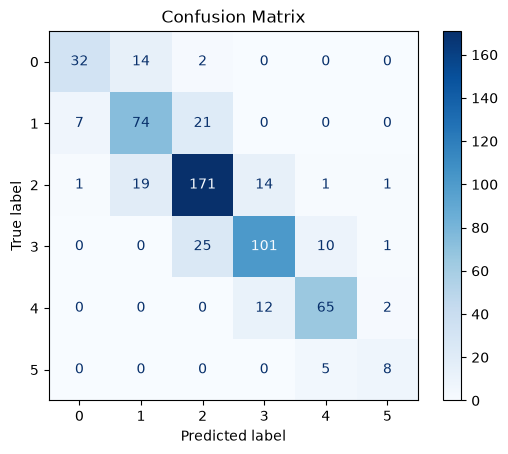

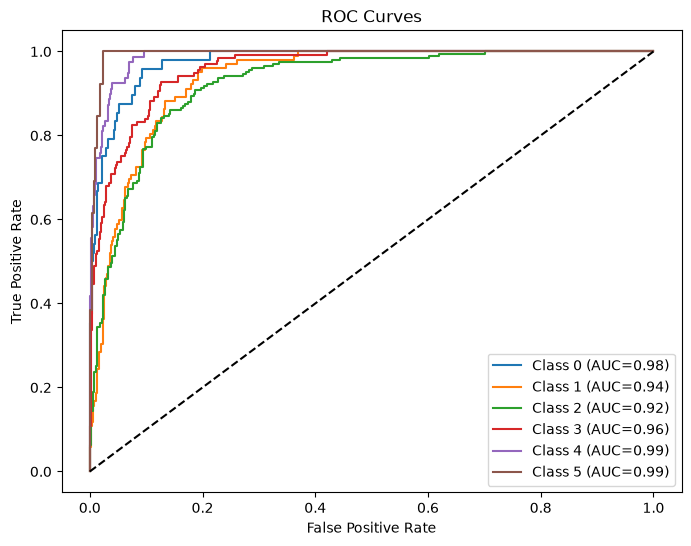

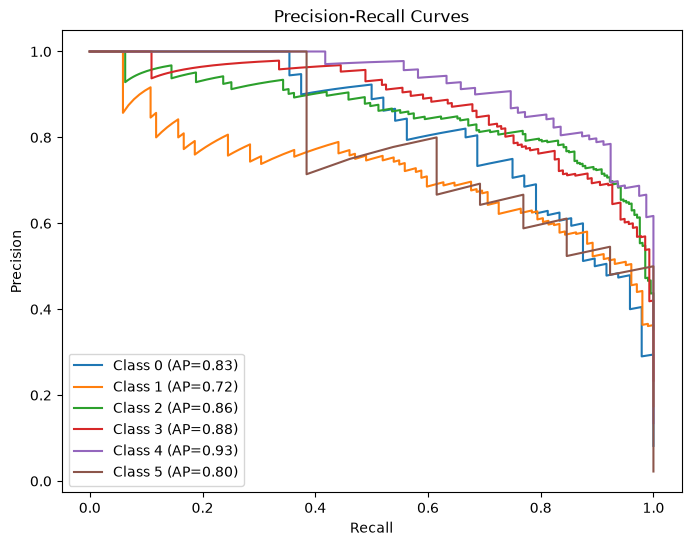

      clasa  precision  recall     f1  support
0     <100k      0.800   0.667  0.727       48
1  100-130k      0.692   0.725  0.708      102
2  130-180k      0.781   0.826  0.803      207
3  180-250k      0.795   0.737  0.765      137
4  250-400k      0.802   0.823  0.812       79
5    >=400k      0.667   0.615  0.640       13


In [9]:
res_lgb_base = metrics_eval.evaluate_model(model_lgb_base, X_test, y_test, show_plots=True)

Interpretarea metricilor modelului de baza

Pe test, LightGBM de baza obtine macro-F1 = 0.7426, accuracy = 0.7696 si macro-recall = 0.7323. Modelul XGBoost de baza din partea B a obtinut macro-F1 = 0.7412, accuracy = 0.7628 si macro-recall = 0.7293, deci cele doua modele de baza sunt practic la acelasi nivel: diferentele sunt sub 0.01.

Matricea de confuzie are aceeasi forma ca la XGBoost: aproape toate greselile sunt intre clase vecine (de exemplu 21 de case din clasa 1 prezise ca 2 si 25 din clasa 3 prezise ca 2). Clasa 5 (>=400k) ramane cea mai slaba: recall 0.615 (8 din 13 case) si F1 0.640, pentru ca modelul de baza nu foloseste ponderi pe clase. ROC-AUC macro (0.9631) si Average Precision macro (0.8341) sunt tot apropiate de XGBoost (0.9637 si 0.8423).

Experimente manuale cu hiperparametrii

La fel ca in partea B, variem cate un singur hiperparametru, cu restul fixati la valorile de baza si 150 de runde, si masuram macro-F1 si logloss pe train si pe CV (5 folduri, aceleasi ca la XGBoost). Hiperparametrii LightGBM analizati:
- num_leaves: numarul maxim de frunze dintr-un arbore, principalul parametru de complexitate
- min_child_samples: numarul minim de case dintr-o frunza (echivalentul lui min_child_weight)
- min_split_gain: castigul minim necesar pentru un split (echivalentul lui gamma)
- subsample si colsample_bytree: fractiunea de case, respectiv de coloane, folosita de fiecare arbore
- reg_lambda: penalizarea L2 pe valorile din frunze
- learning_rate impreuna cu n_estimators

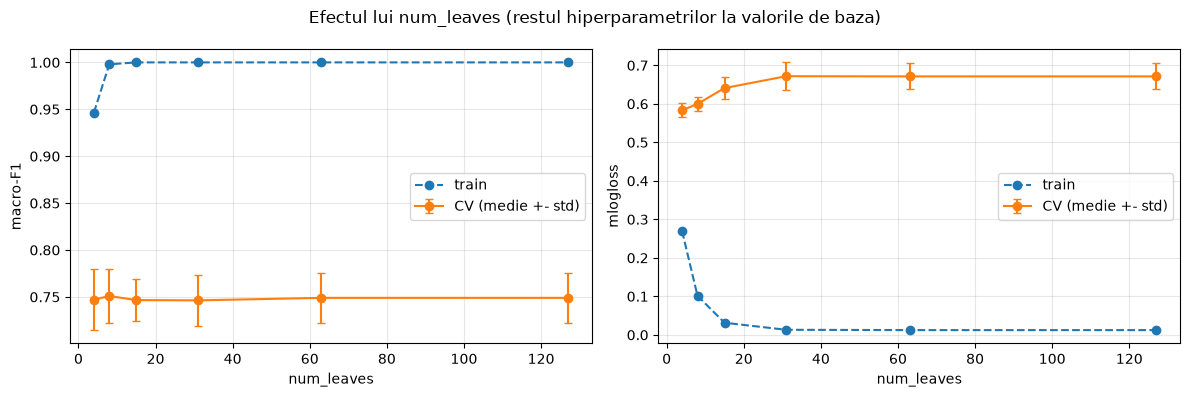

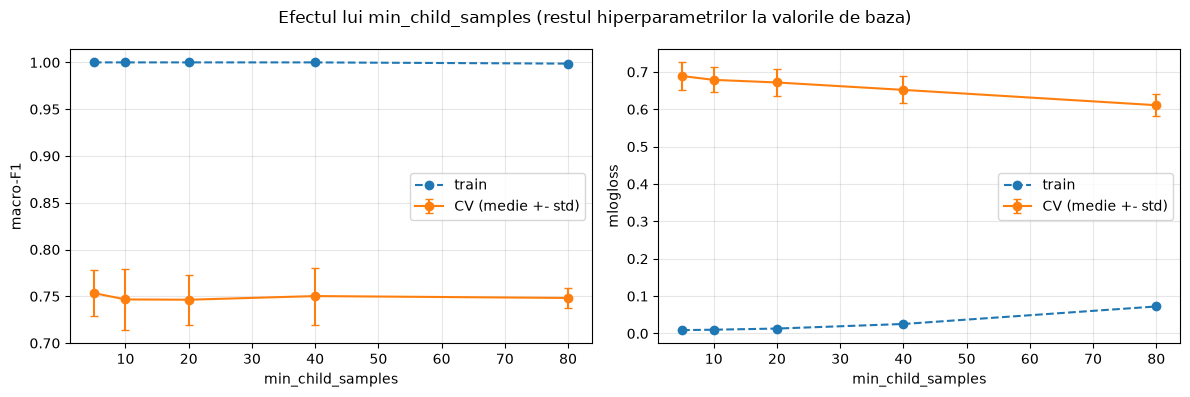

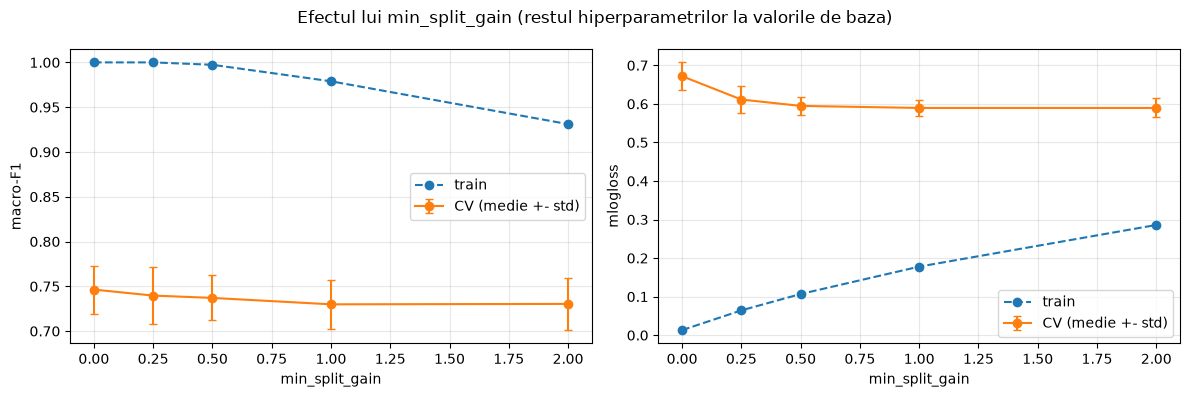

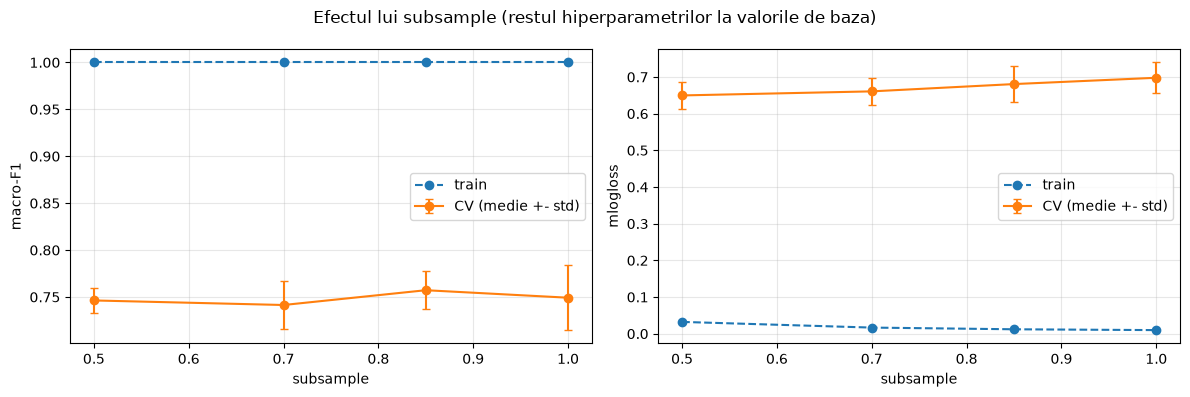

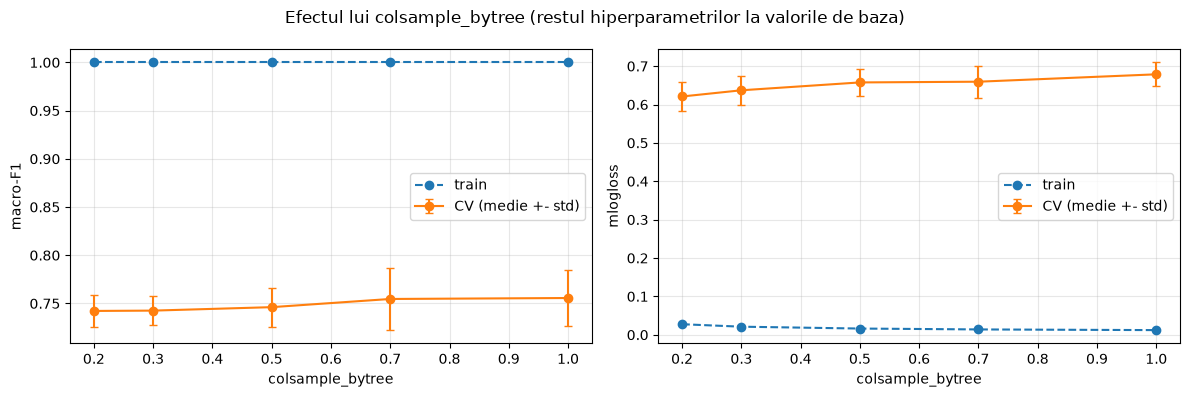

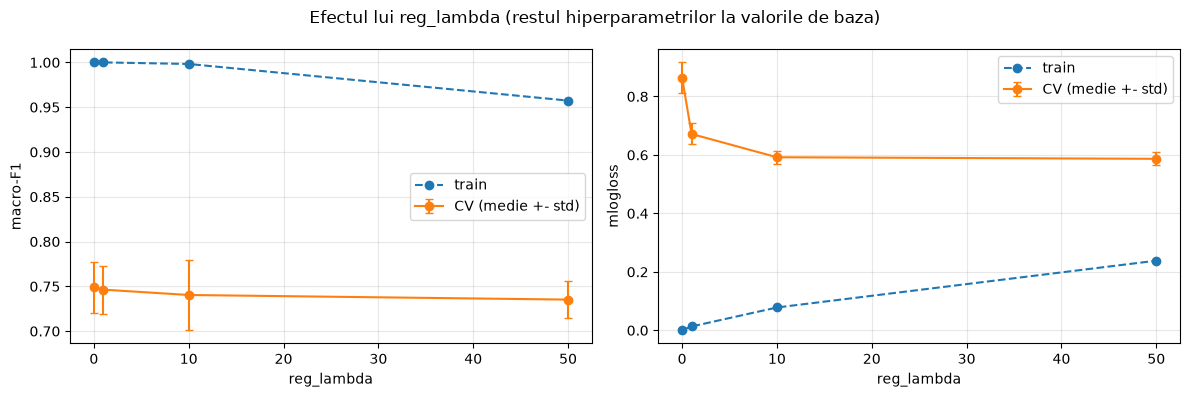

In [10]:
folds = metrics_eval.make_folds(X_train, y_train, preprocessor, n_splits=5)

lgb_sweeps = {}
for name, values in metrics_eval.LGB_SWEEP_GRID.items():
    lgb_sweeps[name] = metrics_eval.lgb_sweep_param(name, values, folds, use_class_weight=False)
    metrics_eval.plot_sweep(lgb_sweeps[name])

In [11]:
rows = []
for name, df_s in lgb_sweeps.items():
    best_value, within = metrics_eval.best_by_sweep(df_s)
    r = df_s.loc[df_s["cv_f1"].idxmax()]
    rows.append({"hiperparametru": name, "cea mai buna valoare": best_value, "CV macro-F1": round(r.cv_f1, 4),
                 "CV std": round(r.cv_f1_std, 4), "train macro-F1": round(r.train_f1, 4),
                 "valori la <=1 std": within})
display(pd.DataFrame(rows))
display(pd.concat(lgb_sweeps.values()).set_index(["param", "value"]).round(4))

,hiperparametru,cea mai buna valoare,CV macro-F1,CV std,train macro-F1,valori la <=1 std
0,num_leaves,8.00,0.7510,0.0291,0.998,"[4, 8, 15, 31, 63, 127]"
1,min_child_samples,5.00,0.7534,0.0244,1.000,"[5, 10, 20, 40, 80]"
2,min_split_gain,0.00,0.7463,0.0268,1.000,"[0.0, 0.25, 0.5, 1.0, 2.0]"
3,subsample,0.85,0.7572,0.0205,1.000,"[0.5, 0.7, 0.85, 1.0]"
4,colsample_bytree,1.00,0.7556,0.0293,1.000,"[0.2, 0.3, 0.5, 0.7, 1.0]"
5,reg_lambda,0.00,0.7490,0.0284,1.000,"[0.0, 1.0, 10.0, 50.0]"


train_f1   cv_f1  cv_f1_std  train_logloss  \
param             value                                                
num_leaves        4.00      0.9464  0.7471     0.0324         0.2696   
                  8.00      0.9980  0.7510     0.0291         0.1013   
                  15.00     1.0000  0.7466     0.0223         0.0315   
                  31.00     1.0000  0.7463     0.0268         0.0132   
                  63.00     1.0000  0.7490     0.0268         0.0123   
                  127.00    1.0000  0.7490     0.0268         0.0123   
min_child_samples 5.00      1.0000  0.7534     0.0244         0.0090   
                  10.00     1.0000  0.7466     0.0328         0.0101   
                  20.00     1.0000  0.7463     0.0268         0.0132   
                  40.00     1.0000  0.7502     0.0305         0.0254   
                  80.00     0.9987  0.7482     0.0107         0.0723   
min_split_gain    0.00      1.0000  0.7463     0.0268         0.0132   
                  0.25      1.0000  0.7397     0.0322         0.0644   
                  0.50      0.9973  0.7370     0.0251         0.1068   
                  1.00      0.9789  0.7299     0.0277         0.1779   
                  2.00      0.9311  0.7304     0.0293         0.2859   
subsample         0.50      1.0000  0.7463     0.0134         0.0322   
                  0.70      1.0000  0.7415     0.0256         0.0167   
                  0.85      1.0000  0.7572     0.0205         0.0121   
                  1.00      1.0000  0.7492     0.0345         0.0098   
colsample_bytree  0.20      1.0000  0.7422     0.0165         0.0275   
                  0.30      1.0000  0.7426     0.0151         0.0211   
                  0.50      1.0000  0.7461     0.0203         0.0162   
                  0.70      1.0000  0.7546     0.0323         0.0139   
                  1.00      1.0000  0.7556     0.0293         0.0121   
reg_lambda        0.00      1.0000  0.7490     0.0284         0.0007   
                  1.00      1.0000  0.7463     0.0268         0.0132   
                  10.00     0.9982  0.7404     0.0392         0.0781   
                  50.00     0.9574  0.7352     0.0205         0.2382   

                          cv_logloss  cv_logloss_std  
param             value                               
num_leaves        4.00        0.5832          0.0178  
                  8.00        0.5998          0.0183  
                  15.00       0.6409          0.0288  
                  31.00       0.6718          0.0359  
                  63.00       0.6713          0.0339  
                  127.00      0.6713          0.0339  
min_child_samples 5.00        0.6890          0.0366  
                  10.00       0.6787          0.0332  
                  20.00       0.6718          0.0359  
                  40.00       0.6519          0.0360  
                  80.00       0.6110          0.0289  
min_split_gain    0.00        0.6718          0.0359  
                  0.25        0.6113          0.0352  
                  0.50        0.5947          0.0239  
                  1.00        0.5894          0.0207  
                  2.00        0.5894          0.0246  
subsample         0.50        0.6496          0.0361  
                  0.70        0.6607          0.0374  
                  0.85        0.6806          0.0502  
                  1.00        0.6978          0.0419  
colsample_bytree  0.20        0.6209          0.0369  
                  0.30        0.6370          0.0376  
                  0.50        0.6575          0.0355  
                  0.70        0.6594          0.0421  
                  1.00        0.6787          0.0311  
reg_lambda        0.00        0.8641          0.0525  
                  1.00        0.6718          0.0359  
                  10.00       0.5921          0.0227  
                  50.00       0.5868          0.0226

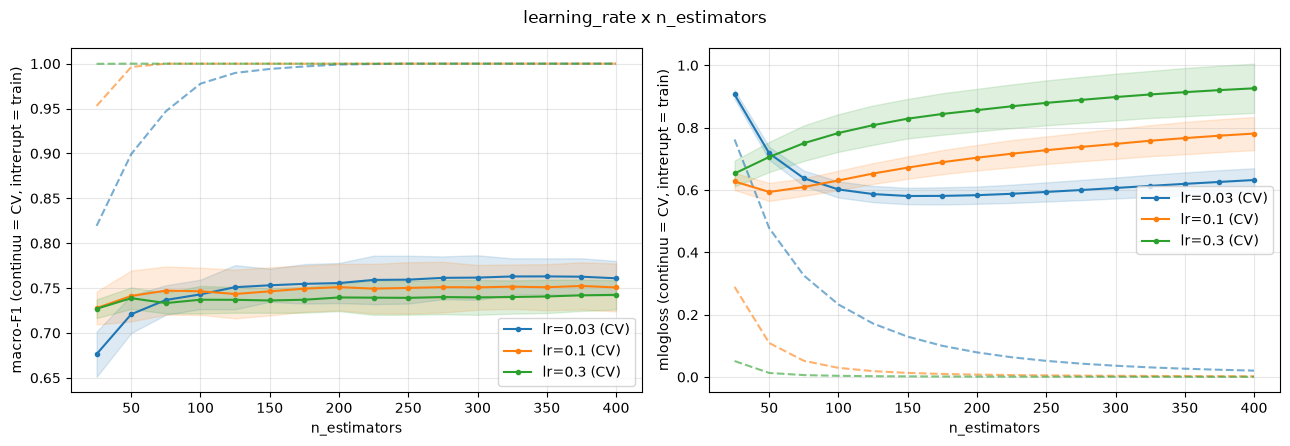

,learning_rate,n_estimators,train_f1,cv_f1,cv_f1_std,cv_logloss
13,0.03,350,1.0,0.7630,0.0201,0.6197
30,0.10,375,1.0,0.7524,0.0263,0.7742
47,0.30,400,1.0,0.7425,0.0163,0.9262


In [12]:
lgb_lr_df = metrics_eval.lgb_sweep_lr_nestimators(folds, learning_rates=(0.03, 0.1, 0.3), max_rounds=400,
                                                  use_class_weight=False)
metrics_eval.plot_lr_nestimators(lgb_lr_df)
display(lgb_lr_df.loc[lgb_lr_df.groupby("learning_rate")["cv_f1"].idxmax(),
                      ["learning_rate", "n_estimators", "train_f1", "cv_f1", "cv_f1_std", "cv_logloss"]].round(4))

Interpretarea experimentelor manuale

Toate comparatiile sunt facute pe aceleasi 5 folduri, cu 150 de runde, learning_rate 0.1 si fara ponderi pe clase, variind un singur parametru.

Observatia principala este ca LightGBM cu parametrii de baza supra-ajusteaza mult mai puternic decat XGBoost. Macro-F1 pe train este 1.000 la aproape toate valorile, iar logloss-ul pe CV al configuratiei de baza este 0.672, fata de 0.578 la XGBoost in partea B. Modelul ajunge sa fie aproape sigur pe fiecare casa din train, dar prea sigur pe casele noi. Ca si la XGBoost, macro-F1 pe CV variaza putin (intre 0.730 si 0.757), cu deviatii standard de 0.01-0.04, deci majoritatea diferentelor de F1 sunt in limita zgomotului. Logloss-ul arata mai clar efectul fiecarui parametru.

- num_leaves (4-127): cu cat arborii sunt mai mici, cu atat logloss-ul pe CV este mai bun (0.583 la 4 frunze, 0.600 la 8, 0.641 la 15, 0.672 la 31). Peste 31 nu se mai schimba nimic, pentru ca arborii nu mai pot creste: min_child_samples = 20 nu permite frunze mai mici. Macro-F1 ramane intre 0.746 si 0.751.
- min_child_samples (5-80): frunze cu mai multe case inseamna un model mai prudent; logloss-ul pe CV scade de la 0.689 (5) la 0.611 (80), fara schimbare clara de F1.
- min_split_gain (0-2): logloss-ul scade de la 0.672 la 0.589, dar macro-F1 scade de la 0.746 la 0.730, iar F1 pe train coboara la 0.931. Valorile peste 0.5 incep sa elimine split-uri utile (underfitting usor).
- subsample (0.5-1.0) si colsample_bytree (0.2-1.0): fractiuni mai mici reduc logloss-ul (subsample 0.698 -> 0.650, colsample_bytree 0.679 -> 0.621), pentru ca arborii devin mai diferiti intre ei. Macro-F1 nu se schimba semnificativ.
- reg_lambda (0-50): fara penalizare (0), modelul este extrem de increzator: logloss pe train 0.0007, dar pe CV 0.864, cea mai slaba valoare din tot studiul. La 10 si 50 logloss-ul se imbunatateste mult (0.592, 0.587), dar la 50 macro-F1 scade la 0.735.
- learning_rate x n_estimators: cu learning_rate 0.3, logloss-ul pe CV atinge minimul dupa aproximativ 25 de runde si apoi creste continuu pana la 0.93; cu 0.1, minimul este la aproximativ 50 de runde si creste apoi pana la 0.78; cu 0.03, curba coboara lent pana la aproximativ 0.58 in jur de 150 de runde si creste doar usor dupa aceea. Cel mai bun macro-F1 este tot la 0.03 (0.763 la 350 de runde), fata de 0.752 la 0.1 si 0.743 la 0.3.

Concluzia pentru optimizare: LightGBM are nevoie de un learning_rate mic si de regularizare (arbori mai mici, frunze cu mai multe case, esantionare a coloanelor si randurilor). Spatiul de cautare pentru Optuna include de aceea learning_rate de la 0.01, num_leaves de la 4 si colsample_bytree de la 0.2, iar min_split_gain este limitat la 1, pentru ca valorile mai mari scad deja macro-F1.

Optimizarea cu Optuna

Folosim exact acelasi protocol ca pentru XGBoost: TPESampler cu seed 42, macro-F1 mediu pe aceleasi 5 folduri ca obiectiv, ponderile pe clase ca hiperparametru categoric si 50 de incercari. Intervalele de cautare sunt cele din metrics_eval.LGB_SEARCH_SPACE, alese pe baza experimentelor manuale de mai sus.

Rezultatele se salveaza in optuna_lightgbm.db, in radacina proiectului. Celula ruleaza doar incercarile care lipsesc pana la 50: daca studiul este deja complet, doar il incarca din fisier si nu mai antreneaza nimic.

In [13]:
import optuna
from optuna.samplers import TPESampler

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 50


def objective(trial):
    use_weights = trial.suggest_categorical("sample_weight_balanced", [False, True])
    params = {
        "num_leaves": trial.suggest_int("num_leaves", 4, 64, log=True),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 800),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 40, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 1.0),
        "min_split_gain": trial.suggest_float("min_split_gain", 0.0, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 20.0, log=True),
    }
    mean_f1, std_f1 = metrics_eval.lgb_cross_validation(params, folds, use_weights)
    trial.set_user_attr("cv_f1_std", std_f1)
    return mean_f1


study_lgb = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=42),
    study_name="lightgbm_optimization",
    storage=f"sqlite:///{(ROOT / 'optuna_lightgbm.db').as_posix()}",
    load_if_exists=True,
)
done = len([t for t in study_lgb.trials if t.state == optuna.trial.TrialState.COMPLETE])
if done < N_TRIALS:
    t0 = time.perf_counter()
    study_lgb.optimize(objective, n_trials=N_TRIALS - done)
    print(f"Durata cautarii: {(time.perf_counter() - t0) / 60:.1f} minute")
else:
    print("Studiul este deja complet, il incarcam din fisier.")

best_lgb = study_lgb.best_trial
print("Numar de incercari:", len(study_lgb.trials))
print(f"Cel mai bun macro-F1 pe CV: {best_lgb.value:.4f} ± {best_lgb.user_attrs['cv_f1_std']:.4f}")
print("Parametri:", best_lgb.params)

Durata cautarii: 9.7 minute
Numar de incercari: 50
Cel mai bun macro-F1 pe CV: 0.7687 ± 0.0198
Parametri: {'sample_weight_balanced': True, 'num_leaves': 20, 'learning_rate': 0.015490957533208786, 'n_estimators': 655, 'min_child_samples': 7, 'subsample': 0.7430822865586613, 'colsample_bytree': 0.3375730530248315, 'min_split_gain': 0.0699161095807996, 'reg_lambda': 0.04614916877483988}


In [14]:
trials_lgb = study_lgb.trials_dataframe()
display(trials_lgb.sort_values("value", ascending=False).head(10))

,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_learning_rate,params_min_child_samples,params_min_split_gain,params_n_estimators,params_num_leaves,params_reg_lambda,params_sample_weight_balanced,params_subsample,user_attrs_cv_f1_std,system_attrs_tpe:relative_params:0,state
27,27,0.768722,2026-10-31 16:25:42.160628,2026-10-31 16:26:14.917166,0 days 00:00:32.756538,0.337573,0.015491,7,0.069916,655,20,0.046149,True,0.743082,0.019763,"{""colsample_bytree"": 0.3375730530248315, ""lear...",COMPLETE
16,16,0.764048,2026-10-31 16:23:02.638928,2026-10-31 16:23:09.018833,0 days 00:00:06.379905,0.757357,0.040151,11,0.273983,514,25,0.080933,True,0.714132,0.019176,"{""colsample_bytree"": 0.7573572704087841, ""lear...",COMPLETE
49,49,0.762782,2026-10-31 16:30:49.160772,2026-10-31 16:31:05.427949,0 days 00:00:16.267177,0.457457,0.068212,21,0.034865,726,40,0.026752,True,0.684635,0.015814,"{""colsample_bytree"": 0.45745687612814667, ""lea...",COMPLETE
28,28,0.762310,2026-10-31 16:26:14.943618,2026-10-31 16:26:36.915940,0 days 00:00:21.972322,0.558534,0.035211,15,0.050059,754,40,0.017584,True,0.682685,0.011821,"{""colsample_bytree"": 0.5585343536225207, ""lear...",COMPLETE
33,33,0.761667,2026-10-31 16:27:52.620167,2026-10-31 16:28:06.627137,0 days 00:00:14.006970,0.635886,0.051743,21,0.007143,771,47,0.012363,True,0.763763,0.015235,"{""colsample_bytree"": 0.6358860578109091, ""lear...",COMPLETE
9,9,0.760244,2026-10-31 16:22:19.668513,2026-10-31 16:22:28.975588,0 days 00:00:09.307075,0.542033,0.067464,13,0.025419,640,32,0.022707,True,0.761366,0.026679,NaN,COMPLETE
34,34,0.760062,2026-10-31 16:28:06.647623,2026-10-31 16:28:19.812974,0 days 00:00:13.165351,0.617370,0.034524,22,0.041796,741,30,0.090502,True,0.840333,0.021028,"{""colsample_bytree"": 0.6173702972046992, ""lear...",COMPLETE
29,29,0.759136,2026-10-31 16:26:36.935490,2026-10-31 16:27:19.713411,0 days 00:00:42.777921,0.309064,0.033415,7,0.046457,603,18,0.054906,True,0.757182,0.016109,"{""colsample_bytree"": 0.3090635594711246, ""lear...",COMPLETE
43,43,0.758783,2026-10-31 16:29:47.444180,2026-10-31 16:30:04.616259,0 days 00:00:17.172079,0.710602,0.027455,28,0.023744,774,40,0.012053,True,0.727056,0.015700,"{""colsample_bytree"": 0.7106024452649065, ""lear...",COMPLETE
26,26,0.757895,2026-10-31 16:25:18.882882,2026-10-31 16:25:42.137322,0 days 00:00:23.254440,0.399566,0.017672,7,0.188173,762,24,0.016674,True,0.760256,0.016052,"{""colsample_bytree"": 0.3995656188474137, ""lear...",COMPLETE


Vizualizarea procesului de optimizare

In [ ]:
from optuna.visualization import matplotlib as ovm
from optuna.importance import FanovaImportanceEvaluator, PedAnovaImportanceEvaluator

ovm.plot_optimization_history(study_lgb)
plt.show()

# Optuna 5 foloseste implicit PED-ANOVA; il aratam explicit, impreuna cu fANOVA (seed fix, reproductibil)
ax = ovm.plot_param_importances(study_lgb, evaluator=PedAnovaImportanceEvaluator())
ax.set_title("Importanta hiperparametrilor: PED-ANOVA (ce deosebeste cele mai bune incercari)", loc="left")
plt.show()

ax = ovm.plot_param_importances(study_lgb, evaluator=FanovaImportanceEvaluator(seed=42))
ax.set_title("Importanta hiperparametrilor: fANOVA (ce explica variatia scorului in toate incercarile)", loc="left")
plt.show()

ovm.plot_slice(study_lgb, params=["num_leaves", "learning_rate", "min_child_samples", "colsample_bytree"])
plt.show()

Interpretarea optimizarii

Cautarea a durat 9.7 minute pentru 50 de incercari, mai putin decat la XGBoost. Scorurile pe CV sunt intre 0.7172 si 0.7687, cu mediana 0.7527. Cel mai bun rezultat (incercarea 27) este 0.7687 ± 0.020, cu 0.022 peste modelul LightGBM de baza din sweep-uri (0.7463).

Istoricul optimizarii arata ca TPESampler a invatat din incercarile anterioare: media primelor 10 incercari este 0.739, iar a ultimelor 10 este 0.754, iar incercarile foarte slabe (sub 0.73) apar doar in primele 10. Cel mai bun scor s-a imbunatatit la incercarile 9 (0.760), 16 (0.764) si 27 (0.769), dupa care nu a mai crescut. Spre deosebire de XGBoost, unde imbunatatirile se opreau intr-o zona stabila, aici ultima imbunatatire este la incercarea 27, deci mai multe incercari ar putea aduce un castig mic.

Cele mai bune 10 incercari au in comun:
- sample_weight_balanced = True la toate (si la 44 din 50 de incercari). Media cu ponderi este 0.753, fara ponderi 0.732.
- learning_rate mic, intre 0.015 si 0.068, si multe runde (514-774), confirmand experimentele manuale.
- num_leaves intre 18 si 47 si min_child_samples intre 7 si 28: arbori de marime medie.
- subsample 0.68-0.84, colsample_bytree 0.31-0.76, min_split_gain sub 0.28 si reg_lambda sub 0.1: regularizare moderata prin esantionare si slaba prin penalizari.

Cele doua grafice de importanta a hiperparametrilor raspund la intrebari diferite, de aceea le aratam pe amandoua:
- fANOVA masoara cat din variatia scorului, in toate cele 50 de incercari, este explicata de fiecare parametru. Cel mai important este learning_rate (0.34), urmat de sample_weight_balanced (0.31) si n_estimators (0.13). Restul parametrilor explica fiecare sub 0.08.
- PED-ANOVA (metoda implicita in Optuna 5) compara doar cele mai bune incercari cu restul si arata ce le deosebeste. Aici conteaza cel mai mult min_split_gain si subsample, iar sample_weight_balanced are importanta aproape zero. Nu este o contradictie: aproape toate incercarile folosesc ponderi, inclusiv toate cele mai bune, deci ponderile nu deosebesc incercarile foarte bune de cele bune, desi au un efect mare asupra scorului in general. Diferenta finala dintre incercarile foarte bune o fac valorile mici de min_split_gain si subsample in jur de 0.75.

Observatie: cu doar 50 de incercari, importantele sunt estimari aproximative. Le folosim ca indicatii, nu ca valori exacte.

Modelul LightGBM final si evaluarea pe test

Reantrenam LightGBM cu cei mai buni hiperparametri pe tot train-ul si il evaluam o singura data pe test.

Rezultatele modelului:
accuracy: 0.7713
precision_macro: 0.7557
recall_macro: 0.7518
f1_macro: 0.7534
f1_weighted: 0.7713
roc_auc_macro_ovr: 0.9648
average_precision_macro: 0.8579
ROC-AUC per clasa: {0: 0.9759, 1: 0.939, 2: 0.9266, 3: 0.9614, 4: 0.989, 5: 0.9966}
Average Precision per clasa: {0: 0.8363, 1: 0.7516, 2: 0.855, 3: 0.8927, 4: 0.9363, 5: 0.8757}
Matricea de confuzie:
 [[ 35  11   2   0   0   0]
 [ 10  72  20   0   0   0]
 [  1  23 169  12   1   1]
 [  0   0  23 102  11   1]
 [  0   0   0  12  65   2]
 [  0   0   0   0   4   9]]

Classification report:
              precision    recall  f1-score   support

           0       0.76      0.73      0.74        48
           1       0.68      0.71      0.69       102
           2       0.79      0.82      0.80       207
           3       0.81      0.74      0.78       137
           4       0.80      0.82      0.81        79
           5       0.69      0.69      0.69        13

    accuracy                           0.77       5

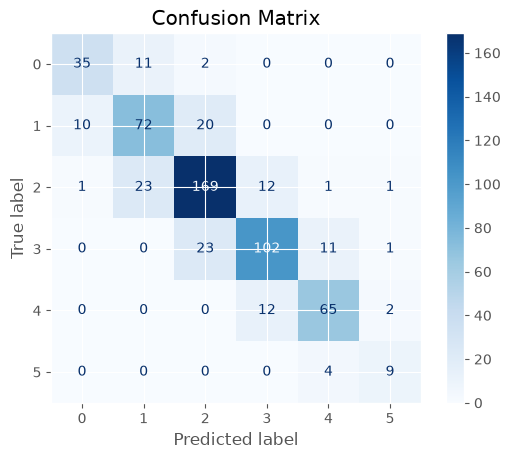

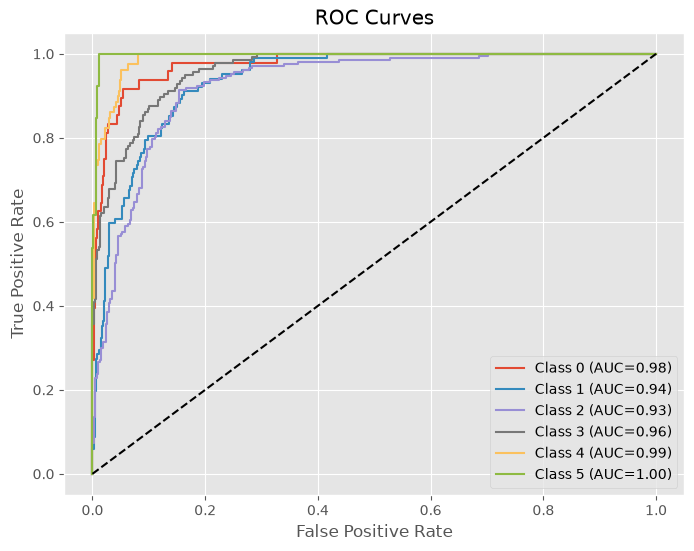

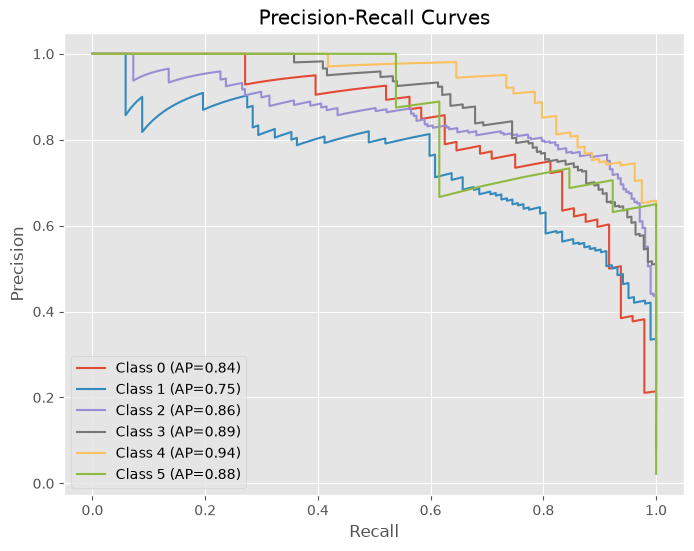

      clasa  precision  recall     f1  support
0     <100k      0.761   0.729  0.745       48
1  100-130k      0.679   0.706  0.692      102
2  130-180k      0.790   0.816  0.803      207
3  180-250k      0.810   0.745  0.776      137
4  250-400k      0.802   0.823  0.812       79
5    >=400k      0.692   0.692  0.692       13


In [16]:
best_params_lgb = dict(study_lgb.best_params)
use_weights_lgb = best_params_lgb.pop("sample_weight_balanced")

t0 = time.perf_counter()
model_lgb_final = metrics_eval.fit_lgb(X_train, y_train, preprocessor, params=best_params_lgb,
                                       use_class_weight=use_weights_lgb, early_stopping=False)
time_lgb = time.perf_counter() - t0
res_lgb = metrics_eval.evaluate_model(model_lgb_final, X_test, y_test, show_plots=True)

Interpretarea modelului LightGBM final

Cu hiperparametrii optimizati (num_leaves = 20, learning_rate = 0.0155, 655 de runde, min_child_samples = 7, subsample = 0.74, colsample_bytree = 0.34, ponderi pe clase), LightGBM obtine pe test macro-F1 = 0.7534, accuracy = 0.7713, macro-recall = 0.7518, ROC-AUC macro = 0.9648 si Average Precision macro = 0.8579.

Fata de modelul LightGBM de baza, macro-F1 creste cu 0.011 si macro-recall cu 0.020. Ca si la XGBoost, castigul vine mai ales din ponderile pe clase, care ajuta clasa 5 (>=400k): recall 0.615 -> 0.692 (9 din 13 case), F1 0.640 -> 0.692, iar Average Precision a clasei 5 creste de la 0.796 la 0.876. Matricea de confuzie pastreaza aceeasi forma: greselile sunt aproape doar intre clase vecine.

Comparatia finala XGBoost vs LightGBM

Pentru XGBoost incarcam studiul Optuna din partea C (optuna_xgboost.db) fara sa rulam din nou cautarea, reantrenam modelul cu cei mai buni hiperparametri si il evaluam pe acelasi test.

In [17]:
study_xgb = optuna.load_study(study_name="xgboost_optimization",
                              storage=f"sqlite:///{(ROOT / 'optuna_xgboost.db').as_posix()}")
best_params_xgb = dict(study_xgb.best_params)
use_weights_xgb = best_params_xgb.pop("sample_weight_balanced")

t0 = time.perf_counter()
model_xgb_final = metrics_eval.fit_xgb(X_train, y_train, preprocessor, params=best_params_xgb,
                                       use_class_weight=use_weights_xgb, early_stopping=False)
time_xgb = time.perf_counter() - t0
res_xgb = metrics_eval.evaluate_model(model_xgb_final, X_test, y_test, show_plots=False)

comparison = pd.DataFrame({
    "XGBoost": {
        "CV macro-F1 (Optuna)": study_xgb.best_value,
        "CV std": study_xgb.best_trial.user_attrs["cv_f1_std"],
        "test macro-F1": res_xgb["f1_macro"],
        "test accuracy": res_xgb["accuracy"],
        "test macro-recall": res_xgb["recall_macro"],
        "test ROC-AUC macro": res_xgb["roc_auc_macro_ovr"],
        "test AP macro": res_xgb["average_precision_macro"],
        "timp antrenare final (s)": time_xgb,
    },
    "LightGBM": {
        "CV macro-F1 (Optuna)": study_lgb.best_value,
        "CV std": study_lgb.best_trial.user_attrs["cv_f1_std"],
        "test macro-F1": res_lgb["f1_macro"],
        "test accuracy": res_lgb["accuracy"],
        "test macro-recall": res_lgb["recall_macro"],
        "test ROC-AUC macro": res_lgb["roc_auc_macro_ovr"],
        "test AP macro": res_lgb["average_precision_macro"],
        "timp antrenare final (s)": time_lgb,
    },
})
display(comparison.round(4))
display(pd.DataFrame({"XGBoost": best_params_xgb | {"sample_weight_balanced": use_weights_xgb},
                      "LightGBM": best_params_lgb | {"sample_weight_balanced": use_weights_lgb}}).T)

Rezultatele modelului:
accuracy: 0.7662
precision_macro: 0.7517
recall_macro: 0.7521
f1_macro: 0.7511
f1_weighted: 0.7661
roc_auc_macro_ovr: 0.9634
average_precision_macro: 0.8529
ROC-AUC per clasa: {0: 0.9796, 1: 0.9379, 2: 0.9199, 3: 0.9572, 4: 0.9896, 5: 0.9962}
Average Precision per clasa: {0: 0.8379, 1: 0.7529, 2: 0.8489, 3: 0.8777, 4: 0.9392, 5: 0.8606}
Matricea de confuzie:
 [[ 35  11   2   0   0   0]
 [ 10  74  18   0   0   0]
 [  1  24 166  14   1   1]
 [  0   0  25  98  13   1]
 [  0   0   0  10  67   2]
 [  0   0   0   0   4   9]]

Classification report:
              precision    recall  f1-score   support

           0       0.76      0.73      0.74        48
           1       0.68      0.73      0.70       102
           2       0.79      0.80      0.79       207
           3       0.80      0.72      0.76       137
           4       0.79      0.85      0.82        79
           5       0.69      0.69      0.69        13

    accuracy                           0.77     

,XGBoost,LightGBM
CV macro-F1 (Optuna),0.7765,0.7687
CV std,0.0159,0.0198
test macro-F1,0.7511,0.7534
test accuracy,0.7662,0.7713
test macro-recall,0.7521,0.7518
test ROC-AUC macro,0.9634,0.9648
test AP macro,0.8529,0.8579
timp antrenare final (s),6.5423,4.7257


,max_depth,learning_rate,n_estimators,subsample,colsample_bytree,min_child_weight,gamma,reg_lambda,sample_weight_balanced,num_leaves,min_child_samples,min_split_gain
XGBoost,7,0.062637,371,0.720522,0.507107,1.33592,0.417389,0.027179,True,NaN,NaN,NaN
LightGBM,NaN,0.015491,655,0.743082,0.337573,NaN,NaN,0.046149,True,20,7,0.069916


In [18]:
per_class = pd.DataFrame({
    "XGBoost F1": metrics_eval.per_class_table(y_test, model_xgb_final.predict(X_test))["f1"].to_numpy(),
    "LightGBM F1": metrics_eval.per_class_table(y_test, model_lgb_final.predict(X_test))["f1"].to_numpy(),
}, index=metrics_eval.CLASS_NAMES)
display(per_class.round(3))

,XGBoost F1,LightGBM F1
<100k,0.745,0.745
100-130k,0.701,0.692
130-180k,0.794,0.803
180-250k,0.757,0.776
250-400k,0.817,0.812
>=400k,0.692,0.692


Comparatia rezultatelor

| Metrica | XGBoost | LightGBM |
|---|---|---|
| CV macro-F1 (Optuna) | 0.7765 ± 0.016 | 0.7687 ± 0.020 |
| test macro-F1 | 0.7511 | 0.7534 |
| test accuracy | 0.7662 | 0.7713 |
| test macro-recall | 0.7521 | 0.7518 |
| test ROC-AUC macro | 0.9634 | 0.9648 |
| test AP macro | 0.8529 | 0.8579 |
| timp antrenare final | 6.5 s | 4.7 s |

Cele doua modele optimizate sunt practic echivalente. Pe CV, XGBoost este putin mai bun (0.7765 fata de 0.7687), iar pe test LightGBM este putin mai bun (0.7534 fata de 0.7511). Ambele diferente sunt mult mai mici decat deviatia standard dintre folduri (aproximativ 0.02), iar faptul ca ordinea se inverseaza intre CV si test arata ca sunt zgomot, nu o superioritate reala a unuia dintre algoritmi.

Pe clase, rezultatele sunt identice la clasele extreme (0 si 5, F1 0.745 si 0.692 la ambele). LightGBM este putin mai bun la clasele 2 si 3 (0.803 fata de 0.794 si 0.776 fata de 0.757), XGBoost la clasele 1 si 4 (0.701 fata de 0.692 si 0.817 fata de 0.812).

Ambele optimizari au ajuns la aceeasi strategie: ponderi pe clase, esantionare a randurilor (subsample in jur de 0.72-0.74) si a coloanelor (colsample_bytree 0.34-0.51) si penalizare L2 slaba. Diferenta este la viteza de invatare: LightGBM a ales un learning_rate de patru ori mai mic (0.0155 fata de 0.063) si mai multe runde (655 fata de 371), pentru ca arborii lui mai mari supra-ajusteaza mai repede.

Timpul de antrenare este mai mic la LightGBM (4.7 s fata de 6.5 s), desi construieste aproape de doua ori mai multi arbori (3930 fata de 2226). Pe arbore, LightGBM este deci de aproximativ 2.5 ori mai rapid, datorita histogramelor si cresterii frunza cu frunza, care concentreaza calculul doar pe frunzele utile. Pe un set de date mic ca al nostru diferenta este de secunde, dar pe seturi mari este motivul principal pentru care se foloseste LightGBM.

Constructia arborilor si procesul de invatare la modelele optimizate

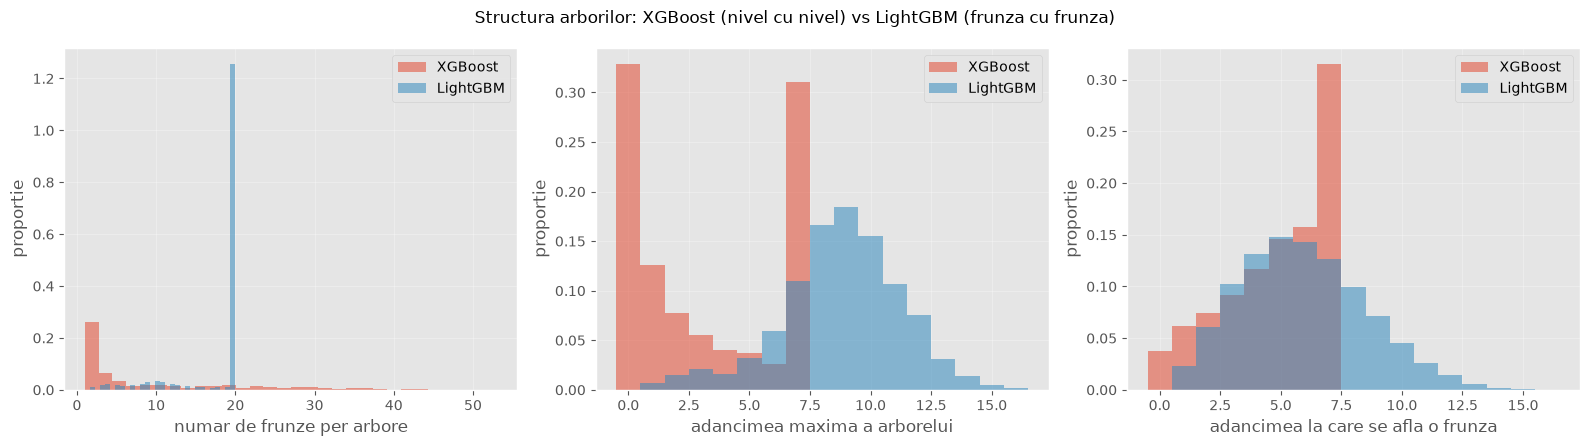

,arbori,frunze/arbore (medie),adancime max (medie),adancime max (maxim),adancimea frunzelor (medie),adancimea frunzelor (std)
model,,,,,,
XGBoost,2226,8.66,3.12,7,4.83,2.11
LightGBM,3930,17.86,8.78,16,5.93,2.58


In [19]:
structure_final = metrics_eval.plot_structure_comparison({"XGBoost": model_xgb_final, "LightGBM": model_lgb_final})
display(structure_final.round(2))

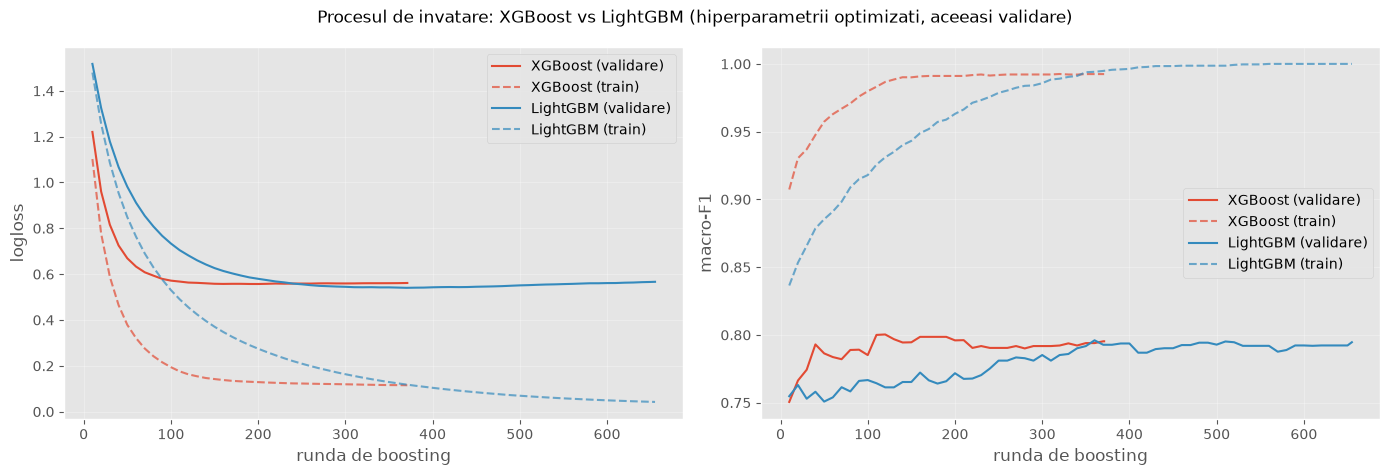

XGBoost     4.09
LightGBM    3.86
Name: timp antrenare (s), dtype: float64

,runda,val_logloss,val_f1
model,,,
LightGBM,370.0,0.5403,0.7927
XGBoost,200.0,0.5570,0.7960


In [20]:
curves, train_times = metrics_eval.compare_learning_curves(
    X_train, y_train, preprocessor,
    {"XGBoost": ("xgboost", best_params_xgb, use_weights_xgb),
     "LightGBM": ("lightgbm", best_params_lgb, use_weights_lgb)},
)
display(train_times.round(2))
display(curves.groupby("model").apply(lambda g: g.loc[g["val_logloss"].idxmin(), ["runda", "val_logloss", "val_f1"]]).round(4))

Interpretarea structurii arborilor si a procesului de invatare

Dupa optimizare, diferenta de structura se pastreaza, dar ambele modele au arbori mai mici decat la modelele de baza. XGBoost (max_depth = 7) are in medie doar 8.7 frunze si adancimea maxima medie 3.1, desi limita este 7: gamma = 0.42 si min_child_weight opresc split-urile cu castig mic, mai ales in arborii de la final, care corecteaza erori mici. LightGBM (num_leaves = 20) are in medie 17.9 frunze, aproape de limita, si adancimea maxima medie 8.8 (maxim 16). Frunzele LightGBM sunt in continuare mai adanci si mai raspandite (adancimea medie 5.9, deviatia standard 2.6) decat la XGBoost (4.8 si 2.1).

Curbele de invatare sunt calculate pe aceeasi impartire fit/validare din train, cu hiperparametrii optimizati:
- XGBoost (learning_rate 0.063) invata repede: logloss-ul pe validare scade sub 0.6 in aproximativ 80 de runde, atinge minimul 0.557 in jur de runda 200 si apoi ramane constant. Macro-F1 pe validare ajunge la aproximativ 0.80 inca de la runda 110, iar pe train la 0.99 in jur de runda 130.
- LightGBM (learning_rate 0.0155) invata mai lent si mai uniform: logloss-ul pe validare atinge minimul 0.540 abia la runda 370, mai jos decat la XGBoost, apoi creste usor pana la aproximativ 0.57 la runda 655. Macro-F1 pe validare creste treptat si ajunge la aproximativ 0.79 dupa 350 de runde, iar pe train ajunge la 1.0 dupa runda 500.

Diferenta dintre train si validare este mare la ambele modele (overfitting), dar logloss-ul pe validare nu creste mult, deci regularizarea aleasa de Optuna tine supra-ajustarea sub control. La LightGBM, ultimele aproximativ 280 de runde nu mai imbunatatesc logloss-ul, dar nici macro-F1 nu scade: ca si in partea B, macro-F1 nu este sensibil la probabilitatile prea increzatoare. Valorile de pe aceasta validare (aproximativ 0.79-0.80) sunt mai mari decat cele de pe CV si test pentru ca sunt calculate pe o singura impartire mica, de 352 de case.

Concluzii pentru bonus

LightGBM, optimizat cu acelasi protocol ca XGBoost, obtine rezultate practic identice: macro-F1 pe test 0.7534 fata de 0.7511 la XGBoost, iar pe CV 0.7687 fata de 0.7765. Diferentele sunt in limita zgomotului, deci pe acest set de date alegerea algoritmului nu schimba semnificativ performanta. Mult mai mult conteaza ponderile pe clase si regularizarea, la care ambele optimizari au ajuns independent.

Diferenta reala dintre cei doi algoritmi este in modul de constructie a arborilor. XGBoost creste arborii nivel cu nivel, rezultand arbori scurti si echilibrati; LightGBM ii creste frunza cu frunza, rezultand arbori adanci si dezechilibrati care reduc eroarea mai repede. Consecintele se vad in tot notebook-ul: LightGBM are nevoie de mai putine runde la acelasi learning_rate, supra-ajusteaza mai repede pe un set de date mic si are nevoie de un learning_rate mai mic si de limite pe frunze, dar este mai rapid pe arbore.

Ambele modele folosesc aceleasi caracteristici, in aceeasi ordine (corelatie Spearman 0.97 intre clasamentele de importanta), iar caracteristicile create in L1 (QualxLivArea, TotalSF, HouseAge) sunt printre cele mai importante la ambele.